# Clustering jerárquico aglomerativo: las notas de 10 estudiantes

**Objetivo:** ver cómo se agrupan estudiantes con notas parecidas, **paso a paso y con gráficos**.

Seguiremos las etapas de las diapositivas: **distancias → cinco parejas → cuatro grupos → tres grupos → dos grupos → dendrograma**.

Usamos las notas originales (0–10), **sin estandarizar**, para conservar las distancias del ejemplo. Si las variables tuvieran escalas diferentes, sería recomendable escalarlas.

,Matemáticas,Ciencias,Español,Historia,Deportes
Lucía,7.0,6.5,9.2,8.6,8.0
Pedro,7.5,9.4,7.3,7.0,7.0
Inés,7.6,9.2,8.0,8.0,7.5
Luis,5.0,6.5,6.5,7.0,9.0
Andrés,6.0,6.0,7.8,8.9,7.3
Ana,7.8,9.6,7.7,8.0,6.5
Carlos,6.3,6.4,8.2,9.0,7.2
José,7.9,9.7,7.5,8.0,6.0
Sonia,6.0,6.0,6.5,5.5,8.7
María,6.8,7.2,8.7,9.0,7.0


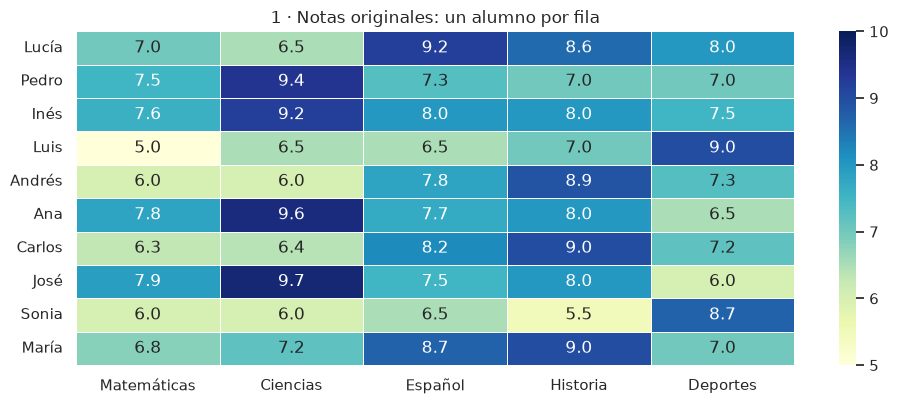

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform, euclidean
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from IPython.display import display

sns.set_theme(style="whitegrid", font_scale=1.0)

nombres = ["Lucía", "Pedro", "Inés", "Luis", "Andrés", "Ana", "Carlos", "José", "Sonia", "María"]
asignaturas = ["Matemáticas", "Ciencias", "Español", "Historia", "Deportes"]
notas = [
    [7.0, 6.5, 9.2, 8.6, 8.0],
    [7.5, 9.4, 7.3, 7.0, 7.0],
    [7.6, 9.2, 8.0, 8.0, 7.5],
    [5.0, 6.5, 6.5, 7.0, 9.0],
    [6.0, 6.0, 7.8, 8.9, 7.3],
    [7.8, 9.6, 7.7, 8.0, 6.5],
    [6.3, 6.4, 8.2, 9.0, 7.2],
    [7.9, 9.7, 7.5, 8.0, 6.0],
    [6.0, 6.0, 6.5, 5.5, 8.7],
    [6.8, 7.2, 8.7, 9.0, 7.0],
]
df = pd.DataFrame(notas, index=nombres, columns=asignaturas)
display(df)

plt.figure(figsize=(10, 4.2))
sns.heatmap(df, annot=True, fmt=".1f", cmap="YlGnBu", vmin=5, vmax=10, linewidths=.5)
plt.title("1 · Notas originales: un alumno por fila")
plt.tight_layout()
plt.show()

## 1. ¿Cómo sabemos si dos estudiantes se parecen?

Calculamos la **distancia euclídea** entre sus cinco notas:

$$d(x,y)=\sqrt{\sum_{i=1}^{5}(x_i-y_i)^2}$$

**Ejemplo:** Lucía y Pedro. Cuanto menor sea la distancia, más parecidos son sus perfiles de notas.

,Lucía,Pedro,Diferencia,Diferencia²
Matemáticas,7.0,7.5,0.5,0.25
Ciencias,6.5,9.4,2.9,8.41
Español,9.2,7.3,-1.9,3.61
Historia,8.6,7.0,-1.6,2.56
Deportes,8.0,7.0,-1.0,1.00


Suma de cuadrados: 15.83  →  raíz cuadrada: 3.98


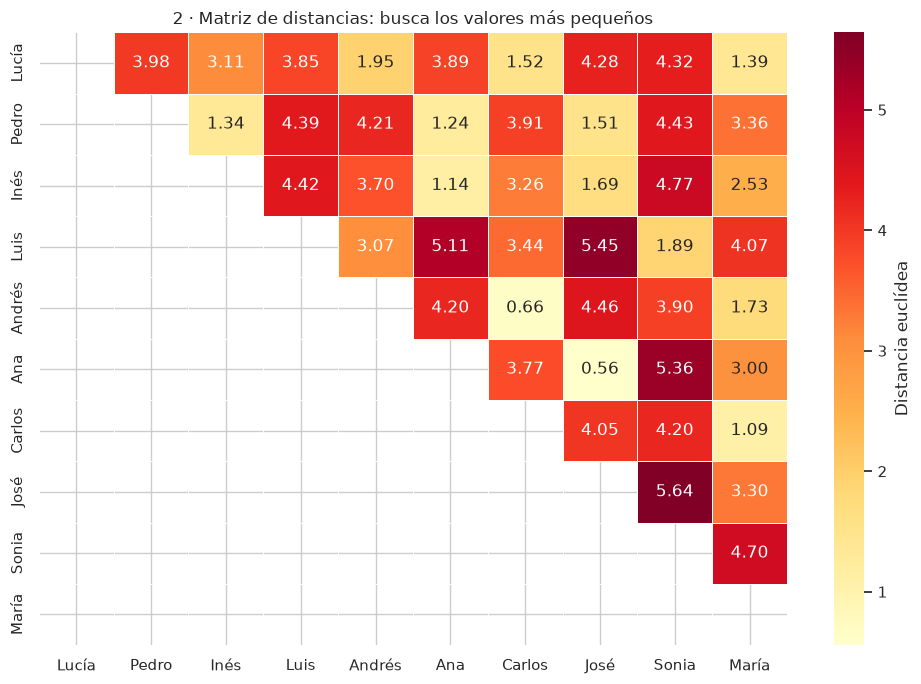

Comprobación: Pedro–Inés = 1.34 y Andrés–Carlos = 0.66


In [2]:
lucia, pedro = df.loc["Lucía"], df.loc["Pedro"]
calculo = pd.DataFrame({"Lucía": lucia, "Pedro": pedro,
                        "Diferencia": pedro - lucia,
                        "Diferencia²": (pedro - lucia)**2})
display(calculo.round(2))
d = euclidean(lucia, pedro)
print(f"Suma de cuadrados: {calculo['Diferencia²'].sum():.2f}  →  raíz cuadrada: {d:.2f}")

# Las distancias entre TODAS las parejas
D = pd.DataFrame(squareform(pdist(df.values, metric="euclidean")), index=nombres, columns=nombres)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(D, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=.4,
            mask=np.tril(np.ones(D.shape, dtype=bool)), ax=ax,
            cbar_kws={"label": "Distancia euclídea"})
ax.set_title("2 · Matriz de distancias: busca los valores más pequeños")
plt.tight_layout()
plt.show()

print("Comprobación: Pedro–Inés = %.2f y Andrés–Carlos = %.2f" % (D.loc["Pedro", "Inés"], D.loc["Andrés", "Carlos"]))

## 2. Cinco parejas iniciales (como en las diapositivas)

Marcamos las cinco parejas para **visualizar la idea de agrupar**. Después calcularemos el centro de cada una.

**Importante:** las diapositivas forman cinco parejas a la vez para simplificar. Un algoritmo aglomerativo real empieza con **10 grupos individuales** y los une **de uno en uno**. Al final veremos el dendrograma del algoritmo auténtico.

Además, en la tabla de las diapositivas están intercambiados dos valores: **Pedro–Inés = 1,34** y **Andrés–Carlos = 0,66**, no al revés.

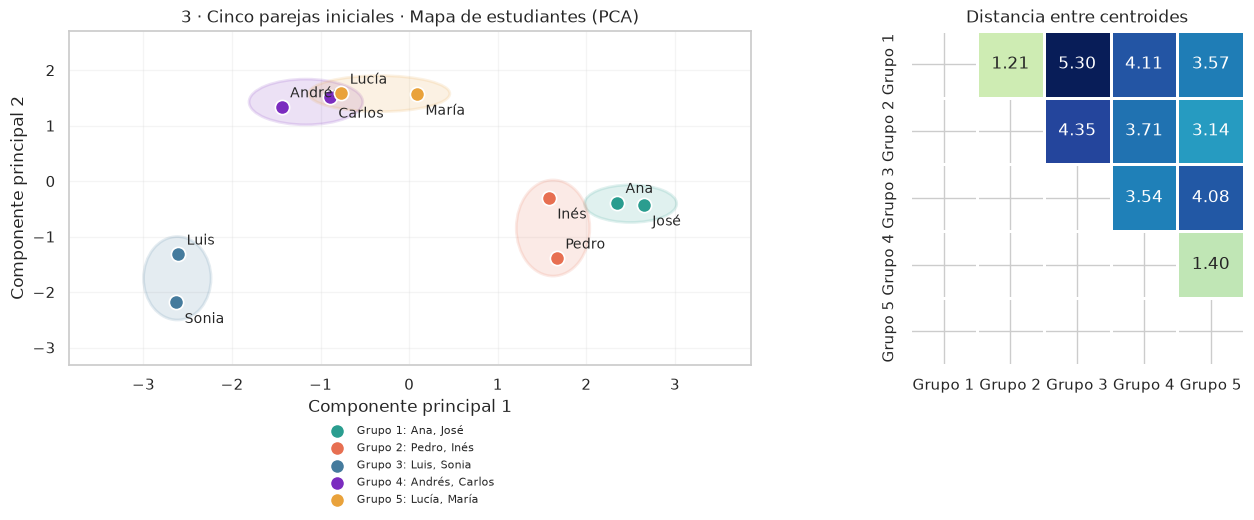

Centroides = media de las 5 notas de los alumnos de cada grupo:


,Matemáticas,Ciencias,Español,Historia,Deportes
Grupo 1,7.85,9.65,7.60,8.00,6.25
Grupo 2,7.55,9.30,7.65,7.50,7.25
Grupo 3,5.50,6.25,6.50,6.25,8.85
Grupo 4,6.15,6.20,8.00,8.95,7.25
Grupo 5,6.90,6.85,8.95,8.80,7.50


Centroides más próximos: Grupo 1 y Grupo 2 (distancia 1.210)


In [3]:
# PCA sirve SOLO para dibujar las 5 asignaturas en 2D.
# Las distancias y los clústeres se calculan SIEMPRE con las 5 notas originales.
proyeccion = pd.DataFrame(PCA(n_components=2).fit_transform(df.values), index=nombres, columns=["PC1", "PC2"])

colores = ["#2a9d8f", "#e76f51", "#457b9d", "#7b2cbf", "#e9a23b"]

def visualizar_grupos(grupos, titulo):
    """Grupos es una lista de listas con los nombres de sus estudiantes."""
    etiquetas = {nombre: f"Grupo {i+1}" for i, grupo in enumerate(grupos) for nombre in grupo}
    centros = pd.DataFrame([df.loc[grupo].mean() for grupo in grupos],
                            index=[f"Grupo {i+1}" for i in range(len(grupos))])
    dist_centros = pd.DataFrame(squareform(pdist(centros.values)), index=centros.index, columns=centros.index)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.15, 1]})
    ax = axes[0]
    # Mismos ejes para que se aprecie la progresión visual entre pasos.
    rx = proyeccion.PC1.max() - proyeccion.PC1.min()
    ry = proyeccion.PC2.max() - proyeccion.PC2.min()
    ax.set_xlim(proyeccion.PC1.min()-.23*rx, proyeccion.PC1.max()+.23*rx)
    ax.set_ylim(proyeccion.PC2.min()-.30*ry, proyeccion.PC2.max()+.30*ry)
    for i, grupo in enumerate(grupos):
        p = proyeccion.loc[grupo]
        color = colores[i % len(colores)]
        ax.scatter(p.PC1, p.PC2, s=105, color=color, edgecolor="white", linewidth=1.2, zorder=3,
                   label=f"Grupo {i+1}: {', '.join(grupo)}")
        if len(grupo) > 1:
            # Sombreado de una zona aproximada en la proyección 2D.
            from matplotlib.patches import Ellipse
            w = (p.PC1.max()-p.PC1.min()) + max(rx*.14, .5)
            h = (p.PC2.max()-p.PC2.min()) + max(ry*.17, .4)
            ellipse = Ellipse((p.PC1.mean(), p.PC2.mean()), w, h,
                              edgecolor=color, facecolor=color, alpha=.14, lw=2)
            ax.add_patch(ellipse)
        for j, (nombre, fila) in enumerate(p.iterrows()):
            ax.annotate(nombre, (fila.PC1, fila.PC2), xytext=(6, 7 if j % 2 == 0 else -15),
                        textcoords="offset points", fontsize=10)
    ax.set_title(f"{titulo} · Mapa de estudiantes (PCA)")
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.15), fontsize=8, frameon=False)
    ax.grid(alpha=.2)
    # Tabla visual de distancias entre los centroides de los grupos.
    mask = np.tril(np.ones(dist_centros.shape, dtype=bool))
    sns.heatmap(dist_centros, annot=True, fmt=".2f", cmap="YlGnBu", mask=mask,
                linewidths=.8, cbar=False, vmin=0, ax=axes[1], square=True)
    axes[1].set_title("Distancia entre centroides")
    fig.tight_layout()
    plt.show()
    print("Centroides = media de las 5 notas de los alumnos de cada grupo:")
    display(centros.round(3))
    if len(grupos) > 1:
        vals = np.where(np.triu(np.ones(dist_centros.shape), 1), dist_centros.values, np.inf)
        a,b = np.unravel_index(np.argmin(vals), vals.shape)
        print(f"Centroides más próximos: Grupo {a+1} y Grupo {b+1} (distancia {vals[a,b]:.3f})")
    return centros

grupos_5 = [["Ana", "José"], ["Pedro", "Inés"], ["Luis", "Sonia"],
            ["Andrés", "Carlos"], ["Lucía", "María"]]
centros_5 = visualizar_grupos(grupos_5, "3 · Cinco parejas iniciales")

## 3. De cinco grupos a cuatro

Los centroides más próximos son los de **Ana–José** y **Pedro–Inés**. Los juntamos, como en la diapositiva. Recalculamos las medias y distancias.

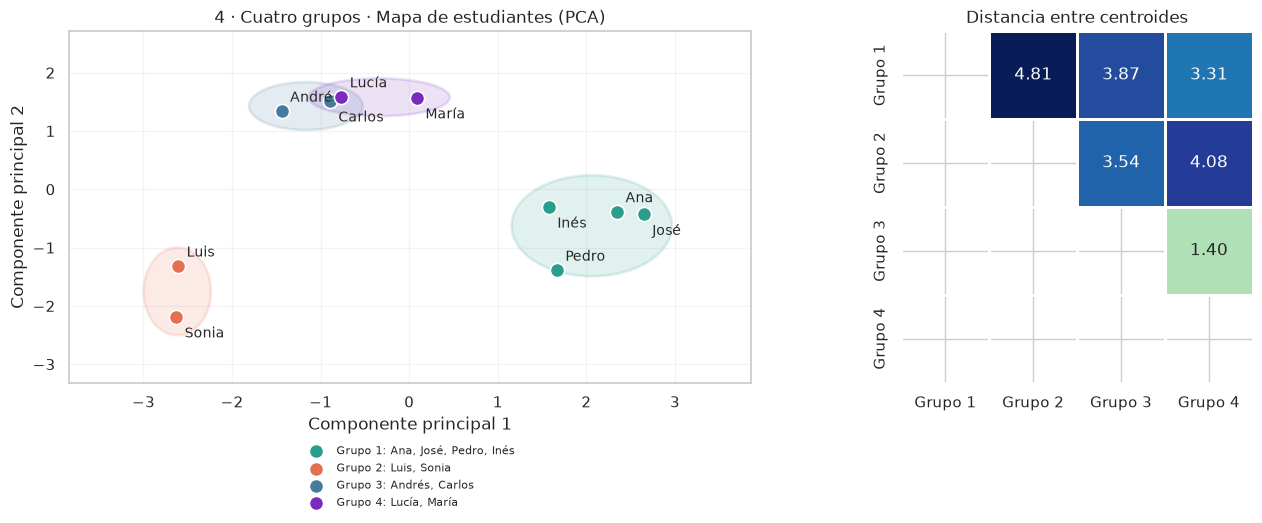

Centroides = media de las 5 notas de los alumnos de cada grupo:


,Matemáticas,Ciencias,Español,Historia,Deportes
Grupo 1,7.70,9.475,7.625,7.75,6.75
Grupo 2,5.50,6.250,6.500,6.25,8.85
Grupo 3,6.15,6.200,8.000,8.95,7.25
Grupo 4,6.90,6.850,8.950,8.80,7.50


Centroides más próximos: Grupo 3 y Grupo 4 (distancia 1.404)


In [4]:
grupos_4 = [["Ana", "José", "Pedro", "Inés"], ["Luis", "Sonia"],
            ["Andrés", "Carlos"], ["Lucía", "María"]]
centros_4 = visualizar_grupos(grupos_4, "4 · Cuatro grupos")

## 4. De cuatro grupos a tres

Ahora se unen **Andrés–Carlos** con **Lucía–María**. Nos quedan tres perfiles claramente diferenciados.

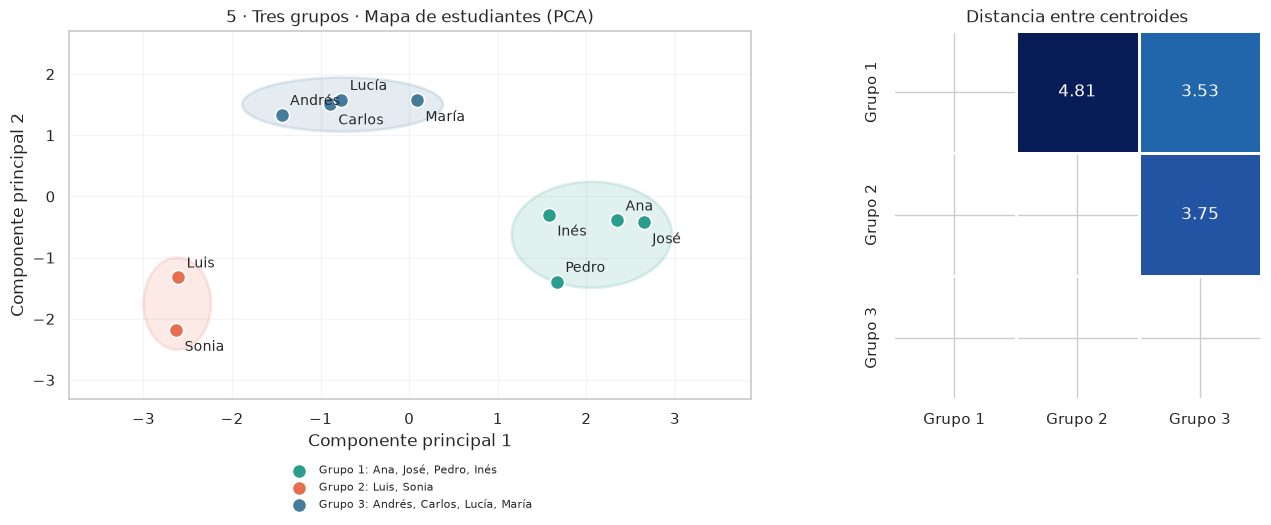

Centroides = media de las 5 notas de los alumnos de cada grupo:


,Matemáticas,Ciencias,Español,Historia,Deportes
Grupo 1,7.700,9.475,7.625,7.750,6.750
Grupo 2,5.500,6.250,6.500,6.250,8.850
Grupo 3,6.525,6.525,8.475,8.875,7.375


Centroides más próximos: Grupo 1 y Grupo 3 (distancia 3.530)


In [5]:
grupos_3 = [["Ana", "José", "Pedro", "Inés"],
            ["Luis", "Sonia"],
            ["Andrés", "Carlos", "Lucía", "María"]]
centros_3 = visualizar_grupos(grupos_3, "5 · Tres grupos")

## 5. De tres grupos a dos

Fusionamos los dos grupos grandes (ocho estudiantes). **Luis y Sonia** quedan juntos en el otro grupo.

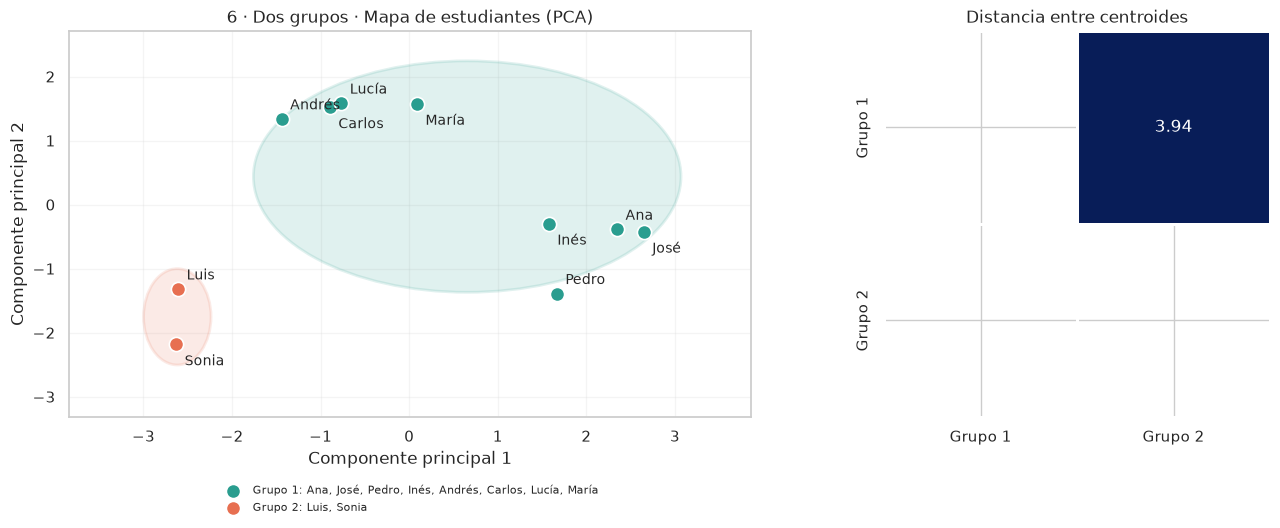

Centroides = media de las 5 notas de los alumnos de cada grupo:


,Matemáticas,Ciencias,Español,Historia,Deportes
Grupo 1,7.112,8.00,8.05,8.312,7.062
Grupo 2,5.500,6.25,6.50,6.250,8.850


Centroides más próximos: Grupo 1 y Grupo 2 (distancia 3.939)


In [6]:
grupos_2 = [["Ana", "José", "Pedro", "Inés", "Andrés", "Carlos", "Lucía", "María"],
            ["Luis", "Sonia"]]
centros_2 = visualizar_grupos(grupos_2, "6 · Dos grupos")

## 6. El dendrograma: el proceso automático de verdad

`scipy.cluster.hierarchy.linkage(method="centroid")` comienza con **diez estudiantes separados** y realiza cada fusión en función de la distancia entre los centroides.

Las **agrupaciones intermedias pueden seguir otro orden** distinto al de las cinco parejas preparadas en las diapositivas. El resultado de **tres grupos**, en estos datos, coincide. La altura indica la distancia entre los centroides en el momento de fusionarlos.

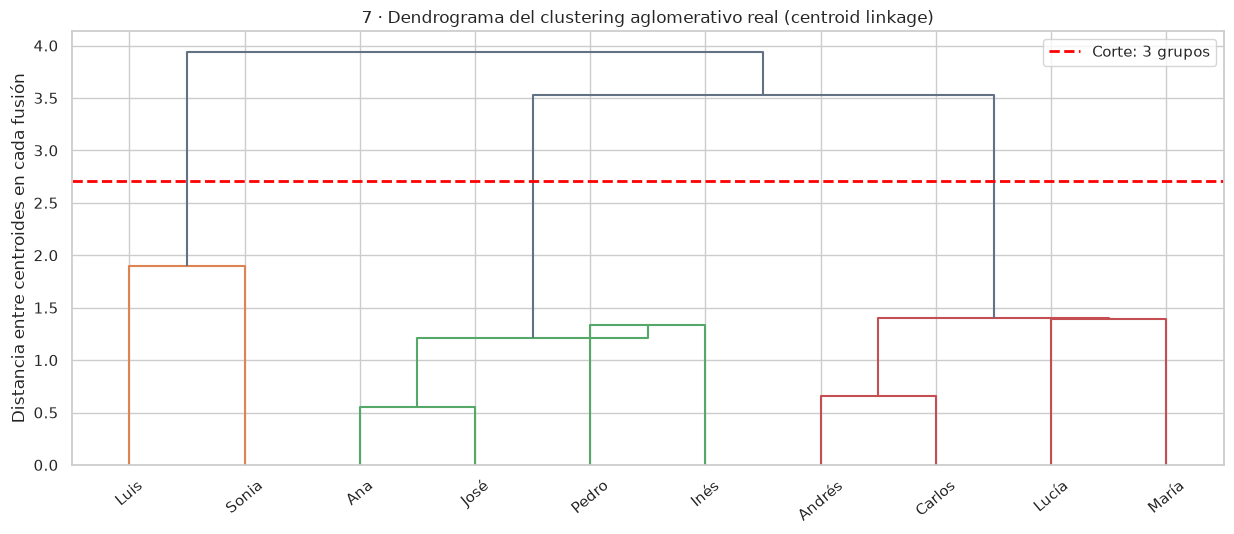

Resultado automático con 3 grupos:
Grupo 1: Luis, Sonia
Grupo 2: Pedro, Inés, Ana, José
Grupo 3: Lucía, Andrés, Carlos, María
✓ Coinciden con los tres grupos de las diapositivas.


In [7]:
Z = linkage(df.values, method="centroid", metric="euclidean")
altura_3 = (Z[-3, 2] + Z[-2, 2]) / 2  # Nivel entre 3 y 2 grupos

fig, ax = plt.subplots(figsize=(12.5, 5.5))
dendrogram(Z, labels=nombres, leaf_rotation=40, leaf_font_size=11,
           color_threshold=altura_3, above_threshold_color="#627184", ax=ax)
ax.axhline(altura_3, color="red", lw=2, ls="--", label="Corte: 3 grupos")
ax.set_title("7 · Dendrograma del clustering aglomerativo real (centroid linkage)")
ax.set_ylabel("Distancia entre centroides en cada fusión")
ax.legend()
plt.tight_layout()
plt.show()

etiquetas_auto = fcluster(Z, t=3, criterion="maxclust")
resultado = pd.DataFrame({"Grupo automático": etiquetas_auto}, index=df.index)
print("Resultado automático con 3 grupos:")
for n, miembros in resultado.groupby("Grupo automático"):
    print(f"Grupo {n}: {', '.join(miembros.index)}")

esperados = {frozenset(g) for g in grupos_3}
obtenidos = {frozenset(g.index) for _,g in resultado.groupby("Grupo automático")}
assert esperados == obtenidos, "Revisar grupos automáticos"
print("✓ Coinciden con los tres grupos de las diapositivas.")

### Para pensar

1. ¿Qué dos estudiantes son más parecidos en sus cinco notas?
2. ¿Por qué al unirse dos grupos hay que **recalcular el centroide**?
3. ¿En qué se diferencia mirar **tres** grupos de mirar **dos**?
4. ¿Por qué el gráfico 2D es solo una **representación** y no sustituye las cinco notas?

**Idea clave:** el método del centroide compara las medias de los grupos. **Ward es otro método:** escoge las fusiones que menos aumentan la variabilidad interna. No son equivalentes.